# Bitcoin OTC: theory comparison and what the findings imply

This notebook explains the results of `scripts/theory_comparison.py`, together with the equal-volume check in `scripts/temporal_sensitivity.py` and the seed-stability check in `scripts/community_profiles.py`. Run `python scripts/reproduce.py` first. Small calculations are repeated here by hand so that each one can be explained in an oral defense. These are descriptive comparisons; none of them identifies a causal mechanism.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import optimize, special
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
THEORY = ROOT / 'outputs' / 'theory'
SENSITIVITY = ROOT / 'outputs' / 'sensitivity'
meta = json.loads((THEORY / 'metadata.json').read_text())
expectations = pd.read_csv(THEORY / 'model_expectations.csv')
tails = pd.read_csv(THEORY / 'degree_tail_fits.csv')
benchmarks = pd.read_csv(THEORY / 'attachment_benchmarks.csv')
returns = pd.read_csv(THEORY / 'reciprocation_by_prior_degree.csv')
thresholds = pd.read_csv(THEORY / 'percolation_thresholds.csv')
centrality = pd.read_csv(THEORY / 'centrality_comparison.csv')
equal_volume = pd.read_csv(SENSITIVITY / 'annual_equal_volume_check.csv')
stability = pd.read_csv(SENSITIVITY / 'community_stability.csv')

## 1. Interpret the centrality measures

Notebook 02 lists the top users. This section says what those numbers mean. **In-degree** counts users who rated someone positively, **out-degree** counts users that person rated, and **betweenness** measures the share of directed shortest paths passing through them. The earlier script estimated betweenness from 64 sampled sources, which is fast but noisy, so we compare it with the exact value.

In [2]:
display(centrality.head(10).round(4))
display(pd.Series(meta['centrality'], name='value').round(3))

,betweenness_rank,node,positive_in_degree,positive_out_degree,betweenness_approx,betweenness_exact,in_degree_rank
0,1,35,535,753,0.1483,0.1425,1
1,2,2642,411,397,0.0725,0.0616,2
2,3,1,226,206,0.0462,0.0440,5
3,4,7,216,225,0.0628,0.0400,7
4,5,905,226,223,0.0389,0.0394,5
5,6,4172,211,190,0.0374,0.0355,8
6,7,1810,270,244,0.0235,0.0354,3
7,8,2028,234,267,0.0378,0.0336,4
8,9,13,190,193,0.0366,0.0300,10
9,10,1953,153,152,0.0478,0.0298,15


spearman_sampled_vs_exact_betweenness       0.951
spearman_in_degree_vs_out_degree            0.837
spearman_in_degree_vs_exact_betweenness     0.868
top_10_overlap_sampled_vs_exact             9.000
top_20_overlap_sampled_vs_exact            13.000
top_10_overlap_in_degree_vs_exact           9.000
Name: value, dtype: float64

In-degree and out-degree move together, as high reciprocity suggests: heavily rated users are also heavy raters. Betweenness largely follows in-degree, so hubs are also the main structural bridges. The differences are more interesting than the agreement. A user can rank high on in-degree yet lower on betweenness when their ratings do not connect otherwise distant accounts. The sampled estimate gets overall ranks about right, but it is noisy for individuals, so individual values should come from the exact column.

High betweenness means a position on shortest paths **in this graph representation**. It does not show that trust or money flowed through that account.

## 2. Compare the network with formula predictions

The earlier notebooks compare the network with **simulated** ER and BA graphs. The course also gives formulas for what those models should produce. Checking both shows the simulations behave as theory says, and shows how far the real network departs. The next cell computes each prediction by hand from $N$ and $L$.

In [3]:
N, L = 5881, 18591
mean_degree = 2 * L / N
p = 2 * L / (N * (N - 1))
giant = optimize.brentq(lambda s: s - 1 + np.exp(-mean_degree * s), 1e-6, 1)
m = round(L / N)

print('ER: <k> =', round(mean_degree, 3), '; p =', round(p, 6))
print('ER: Poisson standard deviation sqrt(<k>) =', round(np.sqrt(mean_degree), 3))
print('ER: giant component S from S = 1 - exp(-<k>S) =', round(giant, 4))
print('ER: mean distance ln N / ln <k> =', round(np.log(N) / np.log(mean_degree), 3))
print('BA: largest hub m sqrt(N) =', round(m * np.sqrt(N), 1))
print('BA: mean distance ln N / ln ln N =', round(np.log(N) / np.log(np.log(N)), 3))
print('BA: clustering scale (ln N)^2 / N =', round(np.log(N) ** 2 / N, 4))

row = expectations.set_index('quantity')
assert np.isclose(giant, row.loc['Largest component share', 'er_formula'])
assert np.isclose(m * np.sqrt(N), row.loc['Maximum degree', 'ba_formula'])
display(expectations.drop(columns=['formula']).round(4))

ER: <k> = 6.322 ; p = 0.001075
ER: Poisson standard deviation sqrt(<k>) = 2.514
ER: giant component S from S = 1 - exp(-<k>S) = 0.9982
ER: mean distance ln N / ln <k> = 4.707
BA: largest hub m sqrt(N) = 230.1
BA: mean distance ln N / ln ln N = 4.016
BA: clustering scale (ln N)^2 / N = 0.0128


,quantity,observed,er_formula,er_simulated_mean,er_simulated_std,ba_formula,ba_simulated_mean,ba_simulated_std,rewired_mean,rewired_std,internal_link_formula,internal_link_simulated_mean,internal_link_simulated_std
0,Mean degree,6.3224,6.3224,6.3224,0.0000,6.0000,5.9969,0.0000,6.3224,0.0000,NaN,6.6823,0.0296
1,Degree standard deviation,20.3638,2.5144,2.4934,0.0238,NaN,8.2756,0.2717,20.3638,0.0000,NaN,23.0772,0.2506
2,Maximum degree,788.0000,17.0000,17.1000,1.1972,230.0630,231.0000,24.2716,788.0000,0.0000,NaN,332.9000,18.5918
3,Heterogeneity <k^2>/<k>,71.9120,7.3224,7.3058,0.0188,NaN,17.4281,0.7475,71.9120,0.0000,NaN,86.3860,1.6442
4,Largest component share,0.9439,0.9982,0.9982,0.0006,1.0000,1.0000,0.0000,0.9272,0.0020,NaN,1.0000,0.0000
5,Mean path length (largest component),3.7610,4.7066,4.9132,0.0539,4.0165,4.0821,0.0702,3.5190,0.0847,NaN,3.4825,0.0593
6,Average local clustering,0.1550,0.0011,0.0010,0.0002,0.0128,0.0081,0.0011,0.0615,0.0019,NaN,0.0974,0.0027
7,Transitivity,0.0570,0.0011,0.0011,0.0002,NaN,0.0042,0.0003,0.0430,0.0011,NaN,0.1164,0.0040
8,Degree assortativity,-0.1449,0.0000,0.0010,0.0067,NaN,-0.0444,0.0053,-0.1144,0.0019,NaN,-0.1421,0.0097
9,Louvain modularity,0.5042,NaN,0.3688,0.0016,NaN,0.3879,0.0019,0.3338,0.0010,NaN,0.3237,0.0014


**Reading the table.** The ER and BA simulations land close to their formulas, which supports the machinery. The observed network differs from both: its largest hub is far beyond either model, and its clustering is far above ER. Local clustering and transitivity both also exceed the degree-preserving rewires, so the degree sequence does not explain all the triangles. Transitivity is hub-dominated, which is why local clustering shows the larger gap. A mean path shorter than ER's, combined with much higher clustering, is the small-world pattern.

In [4]:
display(pd.Series(meta['small_world'], name='value').round(3))
print('Exact mean path:', round(meta['exact_mean_path_largest_component'], 3))
print('Earlier 32-source estimate:', round(meta['sampled_mean_path_stored'], 3))

clustering_ratio_to_er          153.761
path_ratio_to_er                  0.765
clustering_ratio_to_rewired       2.521
path_ratio_to_rewired             1.069
small_world_sigma_vs_er         200.867
small_world_sigma_vs_rewired      2.359
Name: value, dtype: float64

Exact mean path: 3.761
Earlier 32-source estimate: 3.559


## 3. Test the power-law claim properly

The course warns that a straight line on a log-log plot is not evidence. A defensible workflow chooses a lower cutoff $k_{min}$, estimates $\gamma$ by discrete maximum likelihood, reports uncertainty, tests goodness of fit, and compares alternatives.

For discrete data above $k_{min}$, the model is $P(k)=k^{-\gamma}/\zeta(\gamma,k_{min})$. The invented example below finds $\gamma$ by maximizing the likelihood. Its values are not Bitcoin OTC results.

In [5]:
example_degrees = np.array([3, 3, 3, 3, 4, 4, 4, 5, 5, 6, 7, 8, 10, 14, 25], dtype=float)
example_kmin = 3

def negative_log_likelihood(gamma):
    return len(example_degrees) * np.log(special.zeta(gamma, example_kmin)) + gamma * np.log(example_degrees).sum()

example_gamma = optimize.minimize_scalar(negative_log_likelihood, bounds=(1.05, 8), method='bounded').x
print('Invented example: gamma =', round(example_gamma, 3))

Invented example: gamma = 2.285


,0,1,2,3,4
measure,Undirected degree,Positive in-degree,Positive out-degree,BA reference,Internal-link reference
nodes_with_positive_degree,5573,5497,4768,5881,5573
k_min,7.0,9.0,7.0,5.0,2.5
tail_nodes,1089.0,726.0,950.0,NaN,NaN
tail_share,0.195,0.132,0.199,NaN,NaN
gamma,2.09,2.154,2.092,2.744,1.875
gamma_bootstrap_std,0.114,0.146,0.184,0.043,0.036
gamma_ci_low,1.912,1.864,1.932,2.65,1.791
gamma_ci_high,2.238,2.278,2.779,2.791,1.913
k_min_ci_low,3.0,2.0,3.0,NaN,NaN


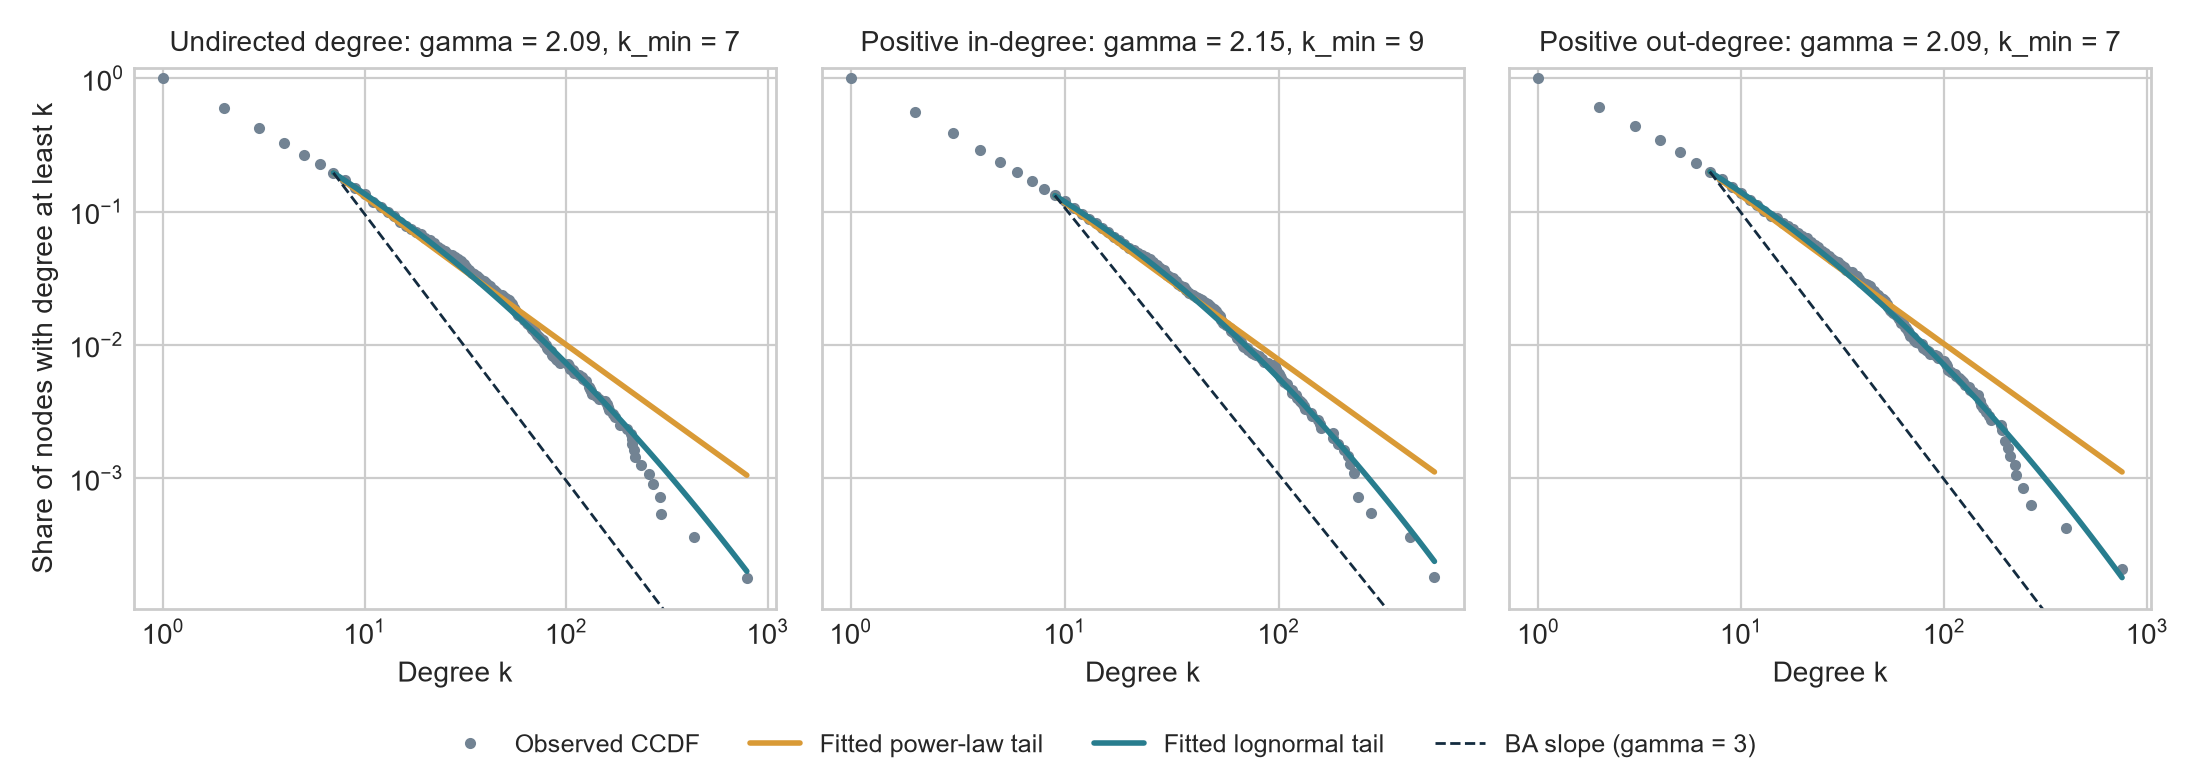

In [6]:
display(tails.drop(columns=['lognormal_mu', 'lognormal_sigma', 'truncated_gamma', 'truncated_rate']).round(3).T)
display(Image(filename=str(THEORY / 'degree_ccdf_fits.png')))

**Reading the fits.** All three exponents are near 2.1, heavier than BA's 3. The estimator applied to known BA graphs returns about 2.7, so it runs somewhat low on finite graphs; the observed value is still clearly below that. However, the goodness-of-fit test rejects the pure power law, and both a lognormal and a power law with an exponential cutoff fit significantly better. The figure shows why: above about $k=100$ the data bend below the straight fit.

The defensible claim is therefore: **the network is strongly heterogeneous and hub-dominated, with a tail heavier than BA's. It is not strictly scale-free.**

## 4. Why BA's growth rule does not fit, and what an extension predicts

BA adds every link together with a new node. The next cell checks this assumption. Each undirected link is classified at the moment it first appears.

In [7]:
growth = meta['growth']
display(pd.Series(growth, name='value').round(4))

users_in_positive_ratings                5573.0000
undirected_links                        18591.0000
links_arriving_with_a_new_user           5491.0000
links_between_existing_users            13100.0000
share_between_existing_users                0.7046
links_per_new_user_m                        0.9853
internal_links_per_new_user_n               2.3506
gamma_double_preferential_attachment        2.1733
Name: value, dtype: float64

Most links join two users who had already appeared, which BA does not allow. Suppose each new user brings $m$ links, $n$ internal links are added per new user, and both ends of an internal link are chosen by degree. Each step adds $m+n$ links, so the sum of degrees is $2(m+n)t$. Then, using the same continuum approach as Week 5:

$$\frac{dk_i}{dt}=\frac{(m+2n)\,k_i}{2(m+n)\,t}\quad\Rightarrow\quad k_i\propto t^{\beta},\ \ \beta=\frac{m+2n}{2(m+n)},\quad\gamma=1+\frac{1}{\beta}=2+\frac{m}{m+2n}.$$

With $n=0$ this returns BA's $\gamma=3$, which is a useful check.

In [8]:
def internal_link_gamma(m, n):
    return 2 + m / (m + 2 * n)

assert internal_link_gamma(3, 0) == 3
predicted = internal_link_gamma(growth['links_per_new_user_m'], growth['internal_links_per_new_user_n'])
undirected = tails.set_index('measure').loc['Undirected degree']
print('Predicted gamma:', round(predicted, 3))
print('Fitted gamma:', round(undirected.gamma, 3), 'interval', round(undirected.gamma_ci_low, 3), 'to', round(undirected.gamma_ci_high, 3))
print('Estimator on simulated internal-link graphs:', round(tails.set_index('measure').loc['Internal-link reference', 'gamma'], 3))

Predicted gamma: 2.173
Fitted gamma: 2.09 interval 1.912 to 2.238
Estimator on simulated internal-link graphs: 1.875


The prediction falls inside the fitted interval, while BA's 3 does not. The estimator runs low on finite graphs, though: it returns about 2.74 on BA graphs and about 1.88 on simulated internal-link graphs. On that common scale, the observed value lies between the two and closer to the extension, so internal links matter without fully accounting for the tail. The simulated extension moves heterogeneity, assortativity, and mean path close to the observed values, but its largest hub is still too small, its transitivity overshoots, its local clustering falls short, and its modularity is far lower (table in Section 2). The rate equation assumes the attachment rule rather than demonstrating it.

## 5. Recipient choice under many benchmarks

Notebooks 03 and 04 compare recipients with uniform and tenure/activity-matched candidates. Here we separate those factors and estimate an attachment exponent $\alpha$, where a candidate's choice probability is proportional to $(k+1)^{\alpha}$. BA assumes linear attachment, $\alpha=1$. Standard errors treat events as independent, so they are optimistic.

,benchmark,events,attachment_exponent_alpha,alpha_standard_error,ratio_0,ratio_2-3,ratio_32+
0,Uniform,27133,1.069,0.005,1.759,0.484,12.697
1,Tenure and activity,26993,0.685,0.009,3.847,0.773,1.649
2,Tenure only,27133,1.388,0.005,1.246,0.491,18.455
3,Activity only,27105,0.363,0.006,3.939,0.773,1.706
4,Tenure and ratings given,26588,0.611,0.009,2.751,0.847,1.440
5,"Uniform, first rating in a pair",13695,1.001,0.007,0.715,0.553,11.088
6,"Tenure and activity, first rating in a pair",13617,0.745,0.013,1.158,0.859,1.631


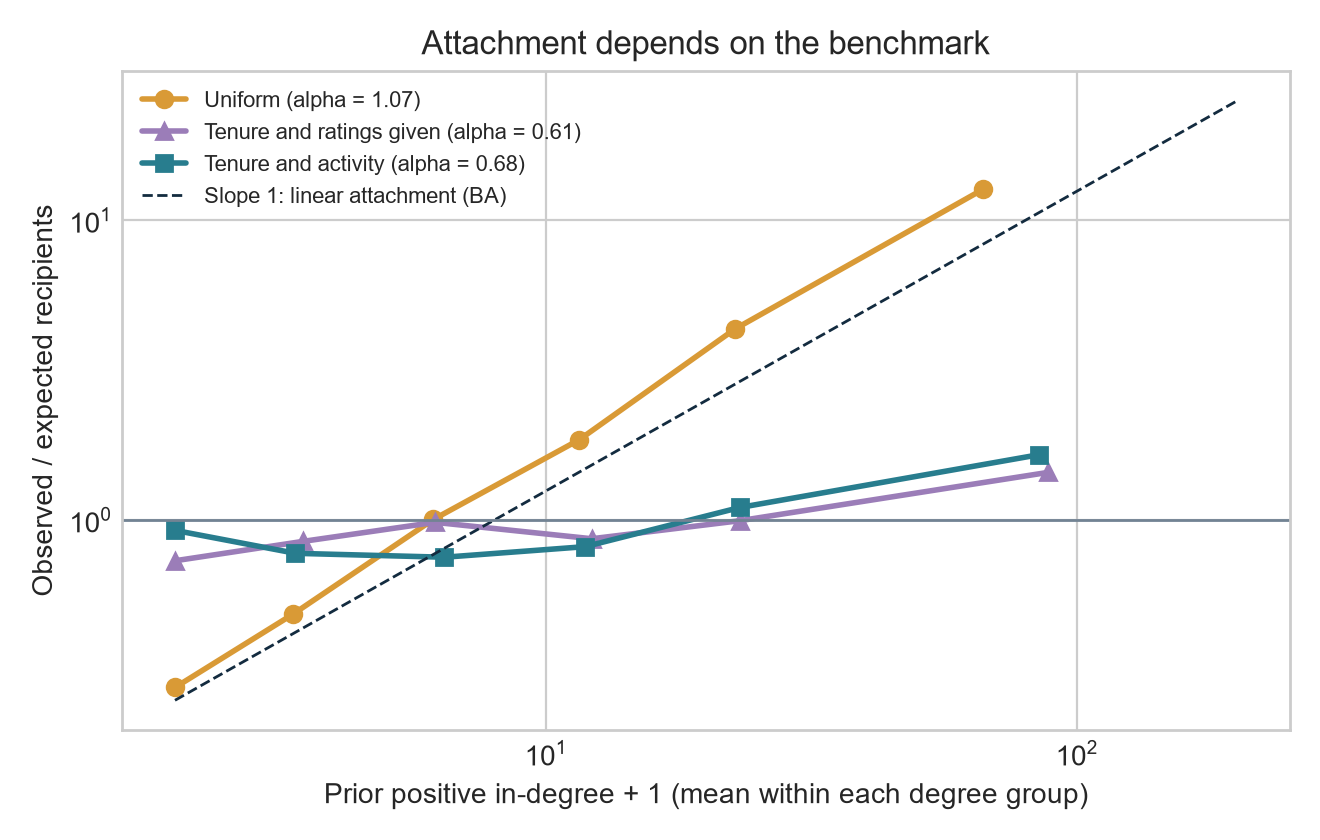

In [9]:
columns = ['benchmark', 'events', 'attachment_exponent_alpha', 'alpha_standard_error', 'ratio_0', 'ratio_2-3', 'ratio_32+']
display(benchmarks[columns].round(3))
display(Image(filename=str(THEORY / 'attachment_kernel.png')))

**Reading the table.**

- Under uniform choice, attachment is close to linear, which at first sight looks like preferential attachment.
- Matching on **tenure alone raises** the 32+ ratio. Matching on **recent activity alone reduces** it to almost the same value as matching on both. Recent activity, not age, does nearly all the work.
- Recent activity includes ratings received, which overlap with prior degree, so the matching could be absorbing the effect it is testing. Counting only ratings the candidate **gave** tests this, and the ratio is even lower. Overlap is therefore not the main explanation.
- A residual remains under every benchmark: high-degree users are still chosen more often than similar peers. We cannot say why.

In [10]:
display(returns.round(3))
display(pd.Series(meta['return_ratings'], name='value').round(4))
print('Median minutes to return:', round(meta['return_ratings']['median_days_to_return'] * 1440, 1))

,prior_positive_in_degree,eligible_events,events_returning_an_earlier_rating,share_returning
0,0,601,477,0.794
1,1,3090,1145,0.371
2,2-3,3717,1578,0.425
3,4-7,4145,1903,0.459
4,8-15,4223,2142,0.507
5,16-31,4001,2049,0.512
6,32+,7356,4144,0.563


eligible_events                       27133.0000
events_returning_an_earlier_rating    13438.0000
share_returning                           0.4953
median_days_to_return                     0.0026
share_returned_within_7_days              0.8730
Name: value, dtype: float64

Median minutes to return: 3.7


About half of eligible events return an earlier rating, with a median delay of a few minutes. These look like mutual feedback after an interaction rather than independent choices. This explains the elevated degree-zero ratio noted in notebook 04: most of those events are returns, and the ratio falls close to 1 when only the first rating in each pair is counted. The 32+ result barely changes, so the high-degree contrast is not a reciprocity artefact.

## 6. Is the fall in yearly concentration real?

Notebook 03 shows the yearly top 1% share falling from 2013 to 2015. Those years are not directly comparable: the top 1% holds 25 users in 2013 but only 4 in 2015, and there are far fewer ratings. The check below redraws every year to the same number of ratings, and also follows the share held by a fixed number of recipients.

In [11]:
display(equal_volume.round(4))

,year,ratings,top_1_percent_share,equal_volume_ratings,equal_volume_share_mean,equal_volume_share_low,equal_volume_share_high,fixed_recipients,fixed_recipients_share,fixed_recipients_equal_volume_mean,fixed_recipients_equal_volume_low,fixed_recipients_equal_volume_high
0,2011,7603,0.1527,743,0.0954,0.0794,0.1117,4,0.0583,0.0642,0.0498,0.0781
1,2012,8622,0.1967,743,0.1121,0.0929,0.1332,4,0.0699,0.0748,0.0592,0.0915
2,2013,11138,0.2096,743,0.1205,0.1009,0.1413,4,0.0729,0.0778,0.0619,0.0956
3,2014,3555,0.1437,743,0.0961,0.0794,0.1157,4,0.0731,0.0786,0.0646,0.0942
4,2015,929,0.1130,743,0.0996,0.0834,0.1225,4,0.1130,0.1156,0.1063,0.1252


At equal volume, the 2013 and 2015 shares have overlapping ranges, and with a fixed number of recipients the share rises rather than falls. **Most of the apparent fall is a volume effect.** The data do not support a claim that new ratings became clearly less concentrated after 2013. The rise in accumulated concentration is unaffected, because it was also checked within a fixed cohort.

## 7. Percolation: formula against simulation

The Molloy–Reed criterion says a giant component needs $\langle k^2\rangle/\langle k\rangle>2$. Random removal of a fraction $f$ therefore destroys it near $f_c=1-1/(\langle k^2\rangle/\langle k\rangle-1)$. For ER, $\langle k^2\rangle/\langle k\rangle=\langle k\rangle+1$, which gives $f_c=1-1/\langle k\rangle$.

ER from the formula: 0.842
Observed from the formula: 0.986


,network,heterogeneity_kappa,molloy_reed_threshold,random_removal_collapse_fraction,targeted_removal_collapse_fraction
0,Observed,71.912,0.986,0.93,0.150
1,Rewired,71.912,0.986,0.94,0.150
2,BA,16.053,0.934,0.90,0.300
3,ER,7.330,0.842,0.85,0.625


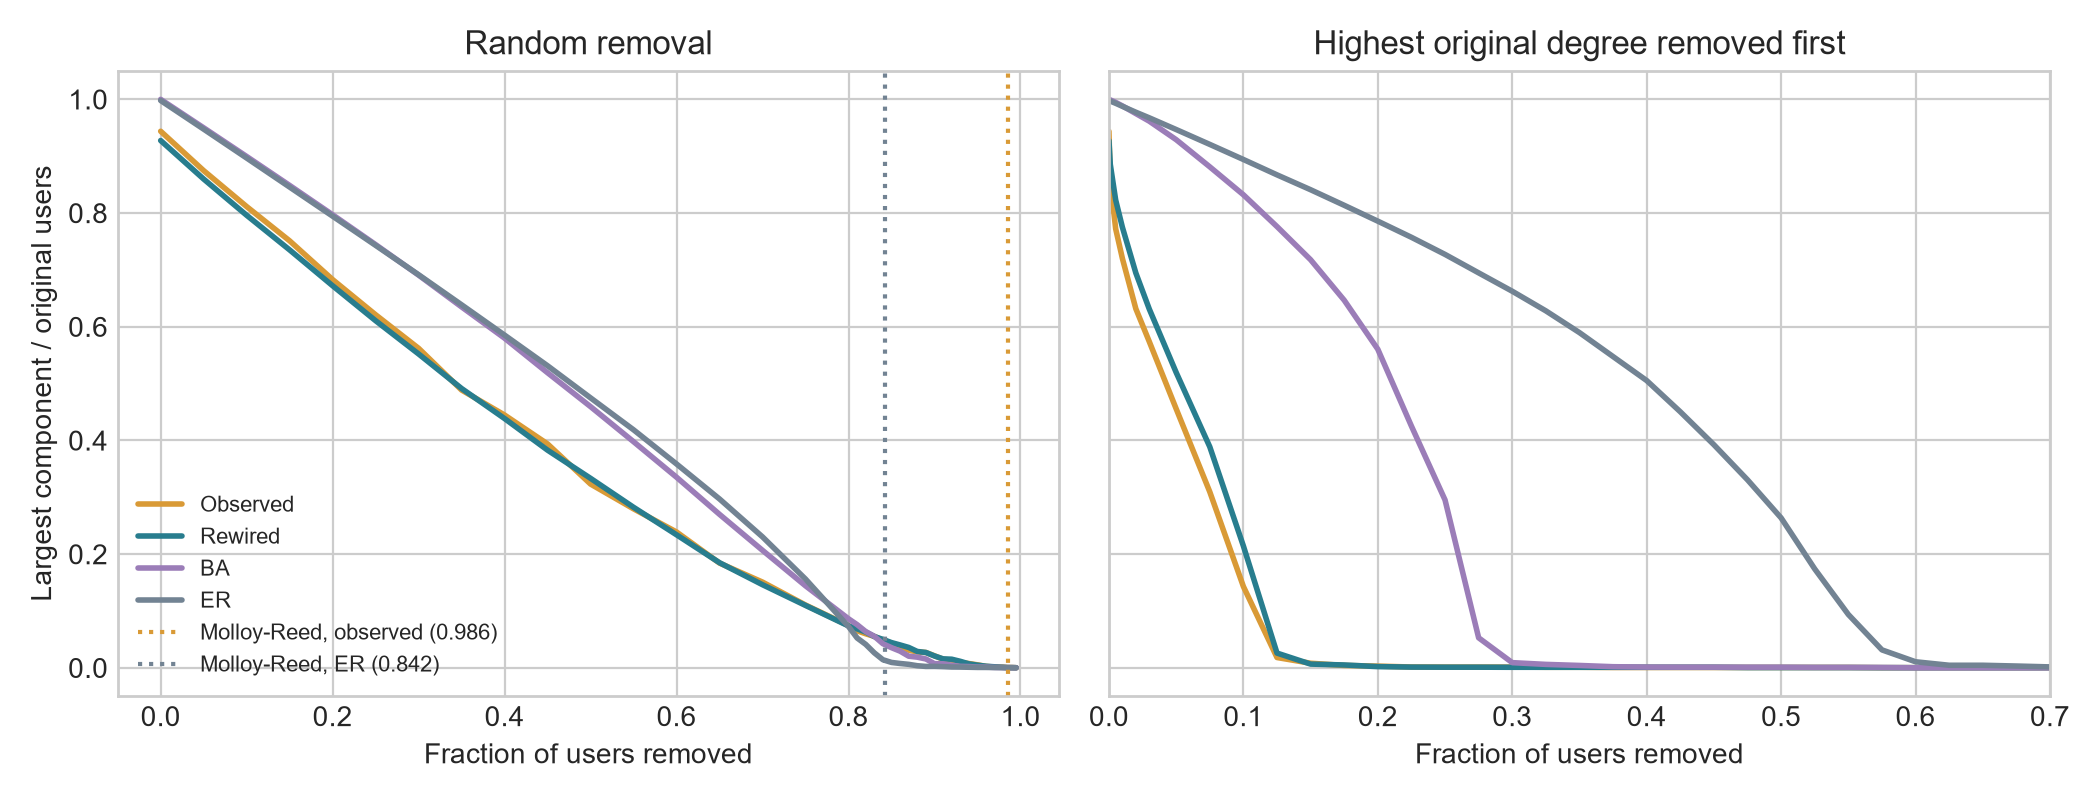

In [12]:
def molloy_reed(kappa):
    return 1 - 1 / (kappa - 1)

print('ER from the formula:', round(1 - 1 / mean_degree, 3))
print('Observed from the formula:', round(molloy_reed(thresholds.set_index('network').loc['Observed', 'heterogeneity_kappa']), 3))
display(thresholds.round(3))
display(Image(filename=str(THEORY / 'percolation_vs_theory.png')))

Heterogeneous networks tolerate random failure and are fragile to targeted removal, as theory predicts. Simulation reproduces the ordering of the thresholds. The finite observed network collapses somewhat before its theoretical value, which assumes an infinite network with arbitrarily large degrees. The rewired network collapses at the same targeted fraction, so this fragility follows mainly from the degree sequence. This is a hypothetical graph experiment: it does not show that users left or that trade would fail.

## 8. How stable are the communities?

Louvain depends on its seed. The reported partition used one seed, so we reran it across twenty.

In [13]:
display(stability.round(4))
display(stability.drop(columns='seed').describe().loc[['min', 'mean', 'max']].round(3))

,seed,modularity,groups_with_two_or_more_users,largest_group_users,nmi_with_reported_partition,mean_best_jaccard_for_five_largest_groups
0,2026,0.5042,33,1096,1.0000,1.0000
1,2027,0.4966,36,1395,0.6419,0.5717
2,2028,0.5084,31,1139,0.8160,0.8361
3,2029,0.4902,39,1173,0.6336,0.5769
4,2030,0.5055,36,1024,0.6986,0.7038
5,2031,0.4943,38,1294,0.6127,0.5388
6,2032,0.5001,32,1174,0.6267,0.6220
7,2033,0.5001,35,1040,0.6901,0.6596
8,2034,0.5035,36,1325,0.6162,0.5757
9,2035,0.5046,35,1258,0.6495,0.6337


,modularity,groups_with_two_or_more_users,largest_group_users,nmi_with_reported_partition,mean_best_jaccard_for_five_largest_groups
min,0.487,28.00,1024.00,0.606,0.530
mean,0.502,35.15,1228.45,0.673,0.637
max,0.517,39.00,1457.00,1.000,1.000


Modularity stays in a narrow band and is clearly above the ER, BA, and rewired values in Section 2, so community organization is a robust property of the network. The largest group's size varies widely and other seeds agree only moderately with the reported partition, so the **membership of any one group is not stable**. We should not attach a social meaning to "Group 1".

## 9. What this implies, and what it cannot show

**For the real system.**

- Reputation is concentrated and stays concentrated. Ratings do not visibly expire in this record and new ratings fell sharply after 2013, so a large accumulated score may increasingly describe past standing.
- The trust record depends on few accounts. Losing or compromising a small share of prominent accounts disconnects far more of the record than the same number of random departures.
- A rating count is not a count of independent endorsements, because about half of eligible ratings return an earlier one, usually within minutes.
- Recent participation appears to matter at least as much as established reputation for attracting ratings, which is encouraging for newcomers. It cannot be separated from unobserved trading volume.

**Limits.** Ratings are opinions, not verified trades or fraud outcomes. The file has no registration dates, exposure, trade volume, or rating changes, and anonymous IDs may not match people one to one. Tenure and activity groups are coarse. Formula values are large-network approximations.

**Further work.** A joint choice model could estimate degree, recency, and reciprocity together and test them out of sample, and could add fitness and aging terms from Week 6. Time-respecting null models would strengthen the temporal comparisons. Signed triad analysis could use the negative ratings, adaptive attacks could recompute degree after each removal, consensus clustering could stabilize the communities, and external fraud labels could test whether network position relates to actual trustworthiness.